# Part 4: Value at Risk and Expected Shortfall

**The question:** how much can an equity portfolio lose in one day, and can we trust the models that answer this?

We move from pricing to risk measurement, on real market data. We estimate the 1-day VaR and Expected Shortfall of an equally weighted portfolio of five CAC 40 stocks worth 1,000,000 EUR, with a closed form, two Monte Carlo models and historical simulation. Then comes the test that matters: a rolling backtest that compares almost 13 years of daily forecasts with the losses that really happened.

**Data.** Daily adjusted close prices from Yahoo Finance (`yfinance`, `auto_adjust=True`), in EUR: LVMH (MC.PA), TotalEnergies (TTE.PA), Sanofi (SAN.PA), BNP Paribas (BNP.PA) and Airbus (AIR.PA). The results below use the download of 2026-10-22. The data is not redistributed: `data/prices.csv` is created the first time this notebook runs, and a later download will extend the period and slightly change the numbers.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import kurtosis, norm, skew

import mc_utils as mc

mc.set_plot_style()
V = 1_000_000.0  # portfolio value in EUR
WINDOW = 500  # estimation window: 500 trading days, about 2 years
rng = np.random.default_rng(42)

prices = mc.load_prices()  # downloads into data/ if data/prices.csv does not exist
returns = np.log(prices).diff().dropna()
weights = np.full(len(prices.columns), 1 / len(prices.columns))

print(
    f"{prices.index[0].date()} to {prices.index[-1].date()}: "
    f"{len(prices)} prices, {len(returns)} daily returns"
)
print("All prices positive:", bool((prices > 0).all().all()))
print("Days with a move above 25% (kept after review):")
print(returns[(returns.abs() > 0.25).any(axis=1)].round(4).to_string())

2012-01-02 to 2026-10-20: 3786 prices, 3785 daily returns
All prices positive: True
Days with a move above 25% (kept after review):
             MC.PA  TTE.PA  SAN.PA  BNP.PA  AIR.PA
Date                                              
2020-03-18 -0.0778 -0.1432 -0.0304 -0.1008 -0.2506


The one flagged move is Airbus on 2020-03-18 (log return -25.06%), during the COVID-19 crash. It is a genuine market move, so it stays in the data.

## 1. Look at the returns

Before modelling risk, we look at the data: daily log returns over the full sample.

In [2]:
portfolio = pd.Series(np.log1p(np.expm1(returns.to_numpy()) @ weights), index=returns.index)
table = returns.assign(Portfolio=portfolio)
pd.DataFrame(
    {
        "annualised volatility": (table.std(ddof=1) * np.sqrt(252)).map("{:.1%}".format),
        "skewness": table.apply(lambda s: skew(s)).map("{:.2f}".format),
        "excess kurtosis": table.apply(lambda s: kurtosis(s)).map("{:.2f}".format),
        "worst day": table.min().map("{:.2%}".format),
        "best day": table.max().map("{:.2%}".format),
    }
)

,annualised volatility,skewness,excess kurtosis,worst day,best day
MC.PA,27.2%,0.16,3.93,-9.08%,12.06%
TTE.PA,25.7%,-0.60,13.26,-18.16%,14.04%
SAN.PA,22.4%,-1.29,17.01,-20.99%,8.10%
BNP.PA,31.3%,-0.45,7.48,-19.12%,16.54%
AIR.PA,33.1%,-0.39,14.91,-25.06%,18.62%
Portfolio,20.7%,-0.59,9.89,-13.02%,11.55%


In [3]:
returns.corr().round(2)

,MC.PA,TTE.PA,SAN.PA,BNP.PA,AIR.PA
MC.PA,1.00,0.41,0.36,0.50,0.48
TTE.PA,0.41,1.00,0.34,0.54,0.44
SAN.PA,0.36,0.34,1.00,0.33,0.28
BNP.PA,0.50,0.54,0.33,1.00,0.54
AIR.PA,0.48,0.44,0.28,0.54,1.00


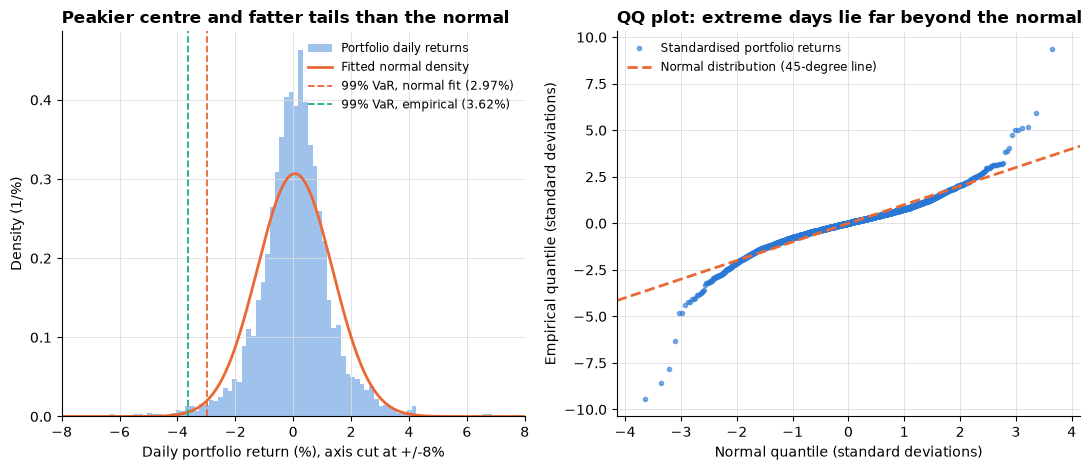

In [4]:
daily = 100 * (np.expm1(returns.to_numpy()) @ weights)  # portfolio simple returns, in %
mu, sd = daily.mean(), daily.std(ddof=1)
var_normal = -(mu + norm.ppf(0.01) * sd)
var_empirical = -np.quantile(daily, 0.01)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.8))
x = np.linspace(daily.min(), daily.max(), 600)
ax1.hist(daily, bins=150, density=True, color=mc.BLUE, alpha=0.45, label="Portfolio daily returns")
ax1.plot(x, norm.pdf(x, mu, sd), color=mc.ORANGE, label="Fitted normal density")
ax1.axvline(
    -var_normal,
    color=mc.ORANGE,
    linestyle="--",
    linewidth=1.3,
    label=f"99% VaR, normal fit ({var_normal:.2f}%)",
)
ax1.axvline(
    -var_empirical,
    color=mc.AQUA,
    linestyle="--",
    linewidth=1.3,
    label=f"99% VaR, empirical ({var_empirical:.2f}%)",
)
ax1.set_xlim(-8, 8)
ax1.set_xlabel("Daily portfolio return (%), axis cut at +/-8%")
ax1.set_ylabel("Density (1/%)")
ax1.set_title("Peakier centre and fatter tails than the normal")
ax1.legend(loc="upper right", fontsize=8.5)

z = (np.sort(daily) - mu) / sd
theory = norm.ppf((np.arange(1, len(z) + 1) - 0.5) / len(z))
limit = abs(theory).max() + 0.5
ax2.plot(
    theory, z, "o", color=mc.BLUE, markersize=3, alpha=0.6, label="Standardised portfolio returns"
)
ax2.plot(
    [-limit, limit],
    [-limit, limit],
    color=mc.ORANGE,
    linestyle="--",
    label="Normal distribution (45-degree line)",
)
ax2.set_xlim(-limit, limit)
ax2.set_xlabel("Normal quantile (standard deviations)")
ax2.set_ylabel("Empirical quantile (standard deviations)")
ax2.set_title("QQ plot: extreme days lie far beyond the normal")
ax2.legend(loc="upper left", fontsize=8.5)
fig.tight_layout()
fig.savefig("figures/09_return_distribution.png")
plt.show()

Every asset and the portfolio have strongly positive excess kurtosis (9.89 for the portfolio; a normal has 0), and the correlations range from 0.28 to 0.54. Returns are **fat-tailed**: over the full sample the empirical 99% quantile (3.62%) is beyond the normal one (2.97%), and on the QQ plot the extreme days lie far from the line.

## 2. Definitions and the four methods

Losses are **positive** numbers. For a confidence level $\alpha$ (95%, 97.5%, 99%; 97.5% is the ES level of the Basel FRTB framework):

$$\mathrm{VaR}_\alpha = \inf\lbrace \ell : P(L \le \ell) \ge \alpha\rbrace, \qquad \mathrm{ES}_\alpha = \mathbb{E}\big[L \mid L \ge \mathrm{VaR}_\alpha\big].$$

VaR says "on 99% of days we lose less than this". ES answers what VaR ignores: how much do we lose on the other 1%? Daily log returns $r_i$ are modelled, but the P&L is computed exactly from simple returns: $L = -V\sum_i w_i (e^{r_i} - 1)$. The mean return is set to zero: over one day it is negligible next to the volatility, and estimating it adds noise.

**Correlated returns by Cholesky.** Write the covariance as $\Sigma = LL^\top$. If $z$ has independent standard normal entries, then $x = Lz$ has covariance $L\,I\,L^\top = \Sigma$: multiplying by $L$ turns independent shocks into shocks with the right volatilities and correlations.

1. **Parametric normal.** The portfolio return is linearised, $\sum_i w_i r_i$, so it is normal with $\sigma_p = \sqrt{w^\top\Sigma w}$. Then $\mathrm{VaR}_\alpha = V z_\alpha\sigma_p$ and $\mathrm{ES}_\alpha = V\sigma_p\,\varphi(z_\alpha)/(1-\alpha)$.
2. **Monte Carlo normal.** The same model, with $x = Lz$ and each scenario revalued exactly.
3. **Monte Carlo Student-t** ($\nu = 5$). $x = \sqrt{\tfrac{\nu-2}{\nu}}\,Lz/\sqrt{W}$ with $W \sim \chi^2_\nu/\nu$. The factor keeps the covariance exactly equal to $\Sigma$, so only the shape changes. One $W$ scales all assets at once, so a turbulent scenario hits every stock together: this is tail dependence, which the normal does not have.
4. **Historical simulation.** Apply each of the last 500 days of raw returns to today's portfolio and read off the quantile and tail mean. Nothing is assumed or simulated.

We add a variant: **Monte Carlo normal with EWMA covariance** (RiskMetrics, $\lambda = 0.94$), where recent days count more and the memory is about $1/(1-\lambda) \approx 17$ days.

**The 95% vs 99% crossover.** A unit-variance $t_5$ has a 95% quantile of $\sqrt{3/5}\times 2.015 = 1.561$, *below* the normal's 1.645, and a 99% quantile of $\sqrt{3/5}\times 3.365 = 2.606$, *above* the normal's 2.326. With the same variance, the t puts more mass in the centre and the far tails and less in the "shoulders", so it can give a lower 95% VaR and a higher 99% VaR.

In [5]:
window = returns.iloc[-WINDOW:]
past = window.to_numpy()
cov = np.cov(past, rowvar=False)
cov_ewma = mc.ewma_covariance(past)
print(f"Estimation window: {window.index[0].date()} to {window.index[-1].date()}")

n_sims = 500_000
one_day = {
    "Parametric normal": mc.parametric_var_es(cov, weights, V),
    "MC normal": mc.mc_normal_var_es(cov, weights, V, n_sims=n_sims, rng=rng),
    "MC Student-t (nu = 5)": mc.mc_student_t_var_es(cov, weights, V, n_sims=n_sims, rng=rng),
    "MC normal, EWMA cov.": mc.mc_normal_var_es(cov_ewma, weights, V, n_sims=n_sims, rng=rng),
    "Historical simulation": mc.historical_var_es(past, weights, V),
}


def risk_table(results, levels):
    rows = {}
    for name, res in results.items():
        rows[name] = {}
        for level in levels:
            rows[name][f"VaR {100 * level:g}%"] = f"{res['var'][level]:,.0f}"
            rows[name][f"ES {100 * level:g}%"] = f"{res['es'][level]:,.0f}"
    return pd.DataFrame(rows).T


risk_table(one_day, mc.LEVELS)

Estimation window: 2024-11-04 to 2026-10-20


,VaR 95%,ES 95%,VaR 97.5%,ES 97.5%,VaR 99%,ES 99%
Parametric normal,"17,077","21,415","20,348","24,271","24,152","27,670"
MC normal,"16,811","21,013","19,998","23,796","23,717","27,071"
MC Student-t (nu = 5),"15,903","22,738","20,278","27,661","26,497","34,880"
"MC normal, EWMA cov.","13,199","16,563","15,761","18,764","18,650","21,379"
Historical simulation,"14,708","23,729","20,070","30,408","28,154","43,331"


- **MC normal reproduces the closed form, up to linearisation.** The MC 99% VaR (23,717 EUR) is 1.8% below the parametric one (24,152 EUR). This gap is not noise (see the uncertainty table in section 3): since $e^r - 1 > r$, a falling stock loses slightly less than the linear formula says, and the exact revaluation captures this.
- **The Student-t crossover appears on real data:** a lower 95% VaR than the normal (15,903 against 16,811) and a higher 99% VaR (26,497 against 23,717). Its ES is higher at every level, because ES looks into the tail itself.
- **Historical simulation gives the largest 99% VaR and ES** (28,154 and 43,331). The window contains a cluster of large losses in spring 2025 (see the backtest figure). Its ES is 1.54 times its VaR, against 1.14 for the normal model: the real tail beyond the VaR is much heavier.
- **EWMA gives the lowest risk** (18,650 at 99%): the most recent weeks were calmer than the two-year average.

## 3. Horizon, tail shape and Monte Carlo noise

**10-day horizon.** The covariance is multiplied by 10 (square-root-of-time rule), and the historical numbers are scaled by $\sqrt{10}$. This assumes i.i.d. returns, so it is only an approximation.

In [6]:
ten_day = {
    "Parametric normal": mc.parametric_var_es(cov, weights, V, (0.99,), horizon=10),
    "MC normal": mc.mc_normal_var_es(cov, weights, V, (0.99,), n_sims, horizon=10, rng=rng),
    "MC Student-t (nu = 5)": mc.mc_student_t_var_es(
        cov, weights, V, (0.99,), n_sims=n_sims, horizon=10, rng=rng
    ),
    "MC normal, EWMA cov.": mc.mc_normal_var_es(
        cov_ewma, weights, V, (0.99,), n_sims, horizon=10, rng=rng
    ),
}
historical = one_day["Historical simulation"]
ten_day["Historical simulation x sqrt(10)"] = {
    "var": {0.99: np.sqrt(10) * historical["var"][0.99]},
    "es": {0.99: np.sqrt(10) * historical["es"][0.99]},
}
risk_table(ten_day, (0.99,))

,VaR 99%,ES 99%
Parametric normal,"76,376","87,501"
MC normal,"72,425","82,523"
MC Student-t (nu = 5),"80,450","104,370"
"MC normal, EWMA cov.","57,221","65,362"
Historical simulation x sqrt(10),"89,031","137,025"


The parametric 10-day VaR is exactly $\sqrt{10}$ times the 1-day value. The MC normal 10-day VaR (72,425) is lower than $\sqrt{10} \times 23{,}717 \approx 75{,}000$, because the convexity of $e^r - 1$ grows with the size of the moves.

**Sensitivity to $\nu$.** Lower $\nu$ means fatter tails. Each row is an independent run, so the $\nu = 5$ row differs slightly from the table above by Monte Carlo noise.

In [7]:
rows = {}
for nu in (4, 5, 8, 30):
    res = mc.mc_student_t_var_es(cov, weights, V, (0.99,), nu=nu, n_sims=n_sims, rng=rng)
    rows[f"nu = {nu}"] = res
rows["normal"] = one_day["MC normal"]
risk_table(rows, (0.99,))

,VaR 99%,ES 99%
nu = 4,"27,138","37,336"
nu = 5,"26,327","34,835"
nu = 8,"25,441","31,420"
nu = 30,"24,275","28,214"
normal,"23,717","27,071"


VaR and ES both rise as the tails get fatter, and the effect on ES is much larger: from 27,071 (normal) to 37,336 ($\nu = 4$).

**Monte Carlo uncertainty.** How much do these numbers move from one run to the next? We repeat the MC normal estimate 100 times with 500,000 scenarios.

In [8]:
runs = [mc.mc_normal_var_es(cov, weights, V, n_sims=n_sims, rng=rng) for _ in range(100)]
rows = []
for level in mc.LEVELS:
    var_values = [run["var"][level] for run in runs]
    es_values = [run["es"][level] for run in runs]
    rows.append(
        {
            "level": f"{100 * level:g}%",
            "mean VaR": f"{np.mean(var_values):,.0f}",
            "std VaR": f"{np.std(var_values, ddof=1):,.1f}",
            "mean ES": f"{np.mean(es_values):,.0f}",
            "std ES": f"{np.std(es_values, ddof=1):,.1f}",
        }
    )
pd.DataFrame(rows)

,level,mean VaR,std VaR,mean ES,std ES
0,95%,"16,837",36.8,"21,079",38.1
1,97.5%,"20,042",42.8,"23,868",46.1
2,99%,"23,754",54.5,"27,178",60.2


At 99% the standard deviation of the VaR is 54.5 EUR, far smaller than the 435 EUR gap with the parametric formula. So that gap is real.

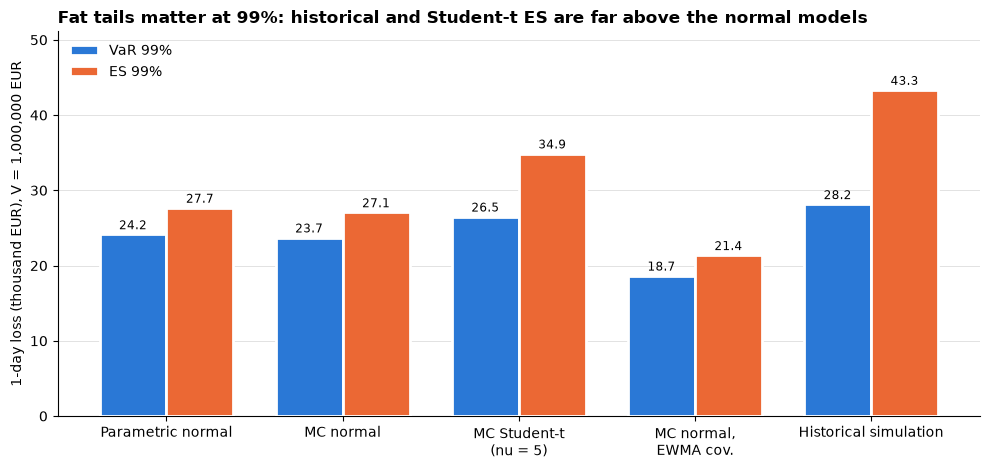

In [9]:
names = list(one_day)
var_99 = [one_day[name]["var"][0.99] / 1e3 for name in names]
es_99 = [one_day[name]["es"][0.99] / 1e3 for name in names]
positions = np.arange(len(names))
width = 0.38

fig, ax = plt.subplots(figsize=(10, 4.8))
for offset, values, color, label in (
    (-width / 2, var_99, mc.BLUE, "VaR 99%"),
    (width / 2, es_99, mc.ORANGE, "ES 99%"),
):
    bars = ax.bar(
        positions + offset,
        values,
        width,
        color=color,
        edgecolor="white",
        linewidth=2,
        label=label,
        zorder=3,
    )
    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value + 0.3,
            f"{value:.1f}",
            ha="center",
            va="bottom",
            fontsize=8.5,
        )
ax.set_xticks(positions, [name.replace(", ", ",\n").replace(" (", "\n(") for name in names])
ax.set_ylabel("1-day loss (thousand EUR), V = 1,000,000 EUR")
ax.set_ylim(0, max(es_99) * 1.18)
ax.grid(axis="x", visible=False)
ax.set_title("Fat tails matter at 99%: historical and Student-t ES are far above the normal models")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig("figures/10_var_es_comparison.png")
plt.show()

## 4. Tail estimates need many scenarios

A quantile is harder to estimate than a mean, because only a small fraction of the scenarios fall near it. We estimate the 99% VaR and ES with 1,000 to 1,000,000 scenarios, 100 times each. The last two columns divide the standard deviation of the estimate by $\sigma_pV/\sqrt{n}$, which is the standard error of a simple *mean* with the same $n$.

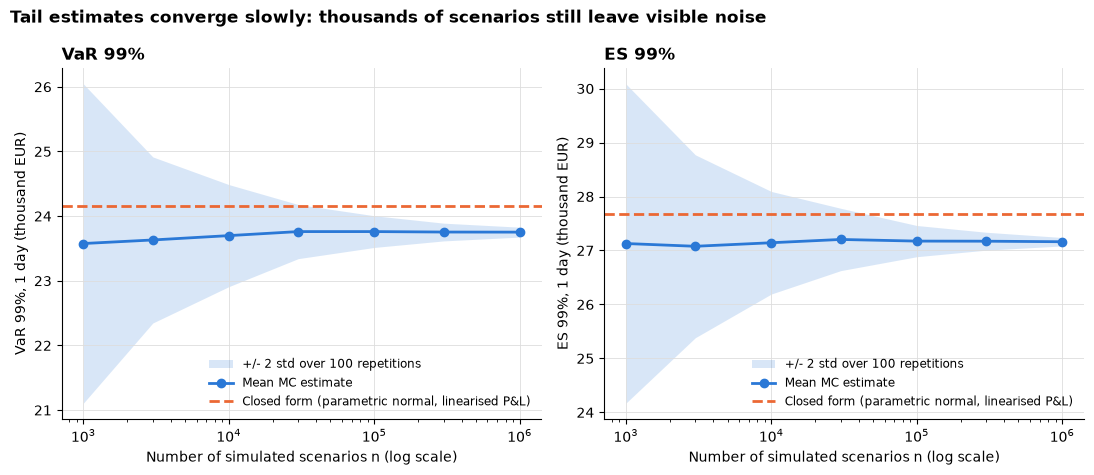

,n,mean VaR,std VaR,mean ES,std ES,std VaR / mean's SE,std ES / mean's SE
0,1000,23576.05,1233.97,27128.93,1478.43,3.76,4.50
1,3000,23631.17,642.10,27077.95,847.24,3.39,4.47
2,10000,23698.35,394.66,27143.49,475.07,3.80,4.58
3,30000,23760.74,209.22,27204.31,288.81,3.49,4.82
4,100000,23760.68,122.60,27173.82,144.62,3.73,4.41
5,300000,23753.72,68.67,27172.09,82.93,3.62,4.38
6,1000000,23752.22,38.37,27162.20,39.11,3.70,3.77


In [10]:
exact = mc.parametric_var_es(cov, weights, V, (0.99,))
sigma_p = float(np.sqrt(weights @ cov @ weights)) * V
rows = []
for n in (1_000, 3_000, 10_000, 30_000, 100_000, 300_000, 1_000_000):
    runs = [mc.mc_normal_var_es(cov, weights, V, (0.99,), n_sims=n, rng=rng) for _ in range(100)]
    var_values = np.array([run["var"][0.99] for run in runs])
    es_values = np.array([run["es"][0.99] for run in runs])
    rows.append(
        {
            "n": n,
            "mean VaR": var_values.mean(),
            "std VaR": var_values.std(ddof=1),
            "mean ES": es_values.mean(),
            "std ES": es_values.std(ddof=1),
            "std VaR / mean's SE": var_values.std(ddof=1) / (sigma_p / np.sqrt(n)),
            "std ES / mean's SE": es_values.std(ddof=1) / (sigma_p / np.sqrt(n)),
        }
    )
convergence = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, label, measure, closed_form in (
    (axes[0], "VaR 99%", "VaR", exact["var"][0.99]),
    (axes[1], "ES 99%", "ES", exact["es"][0.99]),
):
    mean, std = convergence[f"mean {measure}"] / 1e3, convergence[f"std {measure}"] / 1e3
    ax.fill_between(
        convergence["n"],
        mean - 2 * std,
        mean + 2 * std,
        color=mc.BLUE,
        alpha=0.18,
        linewidth=0,
        label="+/- 2 std over 100 repetitions",
    )
    ax.plot(
        convergence["n"], mean, color=mc.BLUE, marker="o", markersize=6, label="Mean MC estimate"
    )
    ax.axhline(
        closed_form / 1e3,
        color=mc.ORANGE,
        linestyle="--",
        label="Closed form (parametric normal, linearised P&L)",
    )
    ax.set_xscale("log")
    ax.set_xlabel("Number of simulated scenarios n (log scale)")
    ax.set_ylabel(f"{label}, 1 day (thousand EUR)")
    ax.set_title(label)
    ax.legend(loc="lower right", fontsize=8.5)
fig.suptitle(
    "Tail estimates converge slowly: thousands of scenarios still leave visible noise",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=12,
)
fig.tight_layout()
fig.savefig("figures/11_convergence.png")
plt.show()
convergence.round(2)

The 99% VaR is about 3.4 to 3.8 times noisier than a mean with the same number of scenarios, and the ES about 3.8 to 4.8 times. (The theoretical value for a normal quantile is $\sqrt{0.99 \times 0.01}/\varphi(z_{0.99}) \approx 3.73$.) Matching the precision of a mean takes roughly $3.7^2 \approx 14$ times more scenarios for VaR, and more for ES. The estimates converge to the exact-P&L value, not to the dashed linearised formula, which explains the gap in the figure.

## 5. Backtest: did the forecasts hold?

For each day from the 501st on, we forecast VaR and ES using only the previous 500 days (no look-ahead), then compare with the realised loss. An **exception** is a day when the loss exceeds the VaR. Each Monte Carlo forecast uses 20,000 scenarios, with the same random draws every day (common random numbers). This removes day-to-day simulation noise, but it makes the Monte Carlo error of consecutive days correlated.

- **Kupiec:** is the exception rate equal to $1-\alpha$?
- **Christoffersen independence:** does an exception today make one tomorrow more likely?
- **Conditional coverage (CC):** both at once.
- **Basel (1996) traffic light:** green (0-4), yellow (5-9) or red (10 or more) from the 99% exceptions of the last 250 days. Used here as an illustration.
- **ES diagnostic** (not a formal test): if the ES is right, the average loss on exception days should be close to the average ES predicted for those days.

In [11]:
NAMES = {
    "parametric_normal": "Parametric normal",
    "mc_normal": "MC normal",
    "mc_student_t": "MC Student-t (nu = 5)",
    "mc_normal_ewma": "MC normal, EWMA cov.",
    "historical": "Historical simulation",
}
bt = mc.rolling_backtest(returns, weights, V, window=WINDOW, rng=rng)
print(f"Backtest: {bt.index[0].date()} to {bt.index[-1].date()}, {len(bt)} days")


def p_value(p):
    return "<0.0001" if p < 1e-4 else f"{p:.4f}"


report = mc.backtest_report(bt, list(NAMES))
pd.DataFrame(
    {
        "method": report["method"].map(NAMES),
        "level": report["level"].map("{:.0%}".format),
        "exceptions": report["exceptions"],
        "expected": report["expected"].round(1),
        "rate": report["rate"].map("{:.2%}".format),
        "Kupiec p": report["kupiec_p"].map(p_value),
        "indep. p": report["independence_p"].map(p_value),
        "CC p": report["cc_p"].map(p_value),
        "last 250 d": report["last_250"].astype(str) + " " + report["zone"],
        "avg loss on exc.": report["avg_loss_on_exceptions"].map("{:,.0f}".format),
        "avg predicted ES": report["avg_predicted_es"].map("{:,.0f}".format),
    }
)

Backtest: 2013-12-18 to 2026-10-20, 3285 days


,method,level,exceptions,expected,rate,Kupiec p,indep. p,CC p,last 250 d,avg loss on exc.,avg predicted ES
0,Parametric normal,99%,63,32.9,1.92%,<0.0001,0.0002,<0.0001,1 green,"41,223","31,701"
1,MC normal,99%,72,32.9,2.19%,<0.0001,0.0002,<0.0001,1 green,"39,731","31,080"
2,MC Student-t (nu = 5),99%,48,32.9,1.46%,0.0129,<0.0001,<0.0001,1 green,"45,811","40,074"
3,"MC normal, EWMA cov.",99%,75,32.9,2.28%,<0.0001,0.0351,<0.0001,5 yellow,"34,258","28,405"
4,Historical simulation,99%,51,32.9,1.55%,0.0032,0.0001,<0.0001,2 green,"42,739","42,226"
5,Parametric normal,95%,150,164.3,4.57%,0.2473,<0.0001,<0.0001,7,"30,533","24,054"
6,MC normal,95%,155,164.3,4.72%,0.4549,<0.0001,<0.0001,7,"30,117","23,522"
7,MC Student-t (nu = 5),95%,174,164.3,5.30%,0.4393,<0.0001,<0.0001,8,"28,939","25,455"
8,"MC normal, EWMA cov.",95%,194,164.3,5.91%,0.0204,<0.0001,<0.0001,13,"25,306","21,384"
9,Historical simulation,95%,176,164.3,5.36%,0.3522,<0.0001,<0.0001,10,"28,975","27,513"


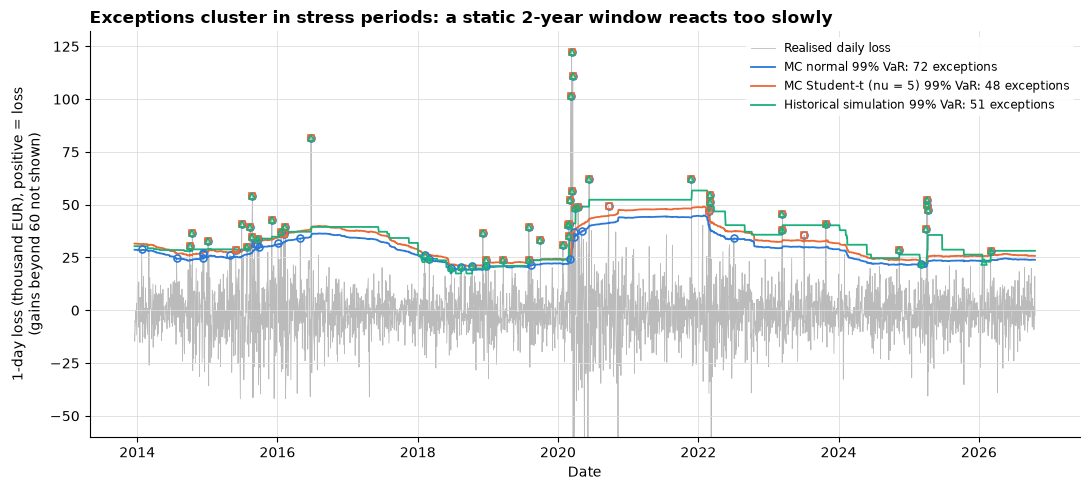

MC normal 99% exceptions per year: 2013: 0, 2014: 7, 2015: 13, 2016: 6, 2017: 0, 2018: 8, 2019: 5, 2020: 17, 2021: 1, 2022: 4, 2023: 4, 2024: 1, 2025: 5, 2026: 1
Days with an exception followed by another one (n11):
  Parametric normal: 7
  MC normal: 8
  MC Student-t (nu = 5): 6
  MC normal, EWMA cov.: 5
  Historical simulation: 6


In [12]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(
    bt.index,
    bt["loss"] / 1e3,
    color="#bbbbbb",
    linewidth=0.6,
    label="Realised daily loss",
    zorder=1,
)
for method, color, marker in (
    ("mc_normal", mc.BLUE, "o"),
    ("mc_student_t", mc.ORANGE, "s"),
    ("historical", mc.AQUA, "^"),
):
    exceptions = bt[f"exc_{method}_99"].to_numpy(dtype=bool)
    ax.plot(
        bt.index,
        bt[f"var_{method}_99"] / 1e3,
        color=color,
        linewidth=1.3,
        label=f"{NAMES[method]} 99% VaR: {exceptions.sum()} exceptions",
        zorder=3,
    )
    ax.plot(
        bt.index[exceptions],
        bt["loss"][exceptions] / 1e3,
        marker,
        color=color,
        markersize=5,
        linestyle="none",
        markerfacecolor="none",
        markeredgewidth=1.2,
        zorder=4,
    )
ax.set_ylabel("1-day loss (thousand EUR), positive = loss\n(gains beyond 60 not shown)")
ax.set_xlabel("Date")
ax.set_ylim(-60, bt["loss"].max() / 1e3 + 10)
ax.set_title("Exceptions cluster in stress periods: a static 2-year window reacts too slowly")
ax.legend(
    loc="upper right",
    fontsize=8.5,
    frameon=True,
    facecolor="white",
    edgecolor="none",
    framealpha=0.9,
)
fig.tight_layout()
fig.savefig("figures/12_backtest_99.png")
plt.show()

by_year = bt["exc_mc_normal_99"].astype(int).groupby(bt.index.year).sum()
print("MC normal 99% exceptions per year:", ", ".join(f"{y}: {n}" for y, n in by_year.items()))
print("Days with an exception followed by another one (n11):")
for method, name in NAMES.items():
    print(f"  {name}: {mc.transition_counts(bt[f'exc_{method}_99'])[3]}")

- **No model passes at 99%.** Every model has too many exceptions, and Kupiec rejects all five at the 5% level. The normal models are worst (63 and 72 exceptions against 32.9 expected). The fat-tailed models come closest: Student-t 48 (p = 0.0129) and historical 51 (p = 0.0032).
- **At 95% the exception rate is fine for four models out of five.** Kupiec only rejects EWMA (p = 0.0204). The normal model is too thin in the far tail, not everywhere. At 95% the Student-t has *more* exceptions than the normal (174 against 155), exactly as its lower 95% VaR predicts.
- **Every model fails the independence test, at both levels.** Exceptions cluster: the MC normal model has 17 of its 72 exceptions in 2020 and 13 in 2015, against 0 in 2017. This is **volatility clustering**: calm and turbulent periods alternate, and a 500-day equally weighted window reacts slowly to both. It also creates a "ghost" effect: the VaR drops sharply in early 2022, when the March 2020 crash leaves the window, although nothing happened in the market that day.
- **EWMA reduces clustering but does not fix the tails.** It has fewer back-to-back exceptions than the MC normal model (5 against 8), and its independence p-value rises from 0.0002 to 0.0351, still a rejection at 5%. But it has the *most* exceptions (75 at 99%, 194 at 95%). It fixes the *level* of volatility, not the *shape* of the distribution: after calm stretches its forecast is low, and its normal tails stay too thin. Combining EWMA with fat tails would address both, but is not implemented here.
- **The normal ES is too optimistic.** On 99% exception days the average loss exceeds the average predicted ES for every model: 39,731 against 31,080 for the MC normal, 45,811 against 40,074 for the Student-t, and only 42,739 against 42,226 for historical simulation, the only model whose ES is close to reality.
- **Small VaR differences matter.** The parametric and MC normal models differ by about 2%, yet have 63 and 72 exceptions: near the 99% quantile, a small change in VaR moves the count noticeably.
- **The traffic light of the last 250 days is green for all models except EWMA** (5 exceptions, yellow). Taken alone, that window would hide the problems the full backtest reveals.

## Key takeaways

- Fat tails matter at 99%: VaR and ES are 23,717 and 27,071 EUR with the normal model, 26,497 and 34,880 with the Student-t, 28,154 and 43,331 with historical simulation.
- Monte Carlo with a normal assumption only recovers the parametric answer. Its value is the freedom to change the distribution, and tail estimates need far more scenarios than a mean.
- No model passes the 99% backtest (48 to 75 exceptions against 32.9 expected), and all fail independence because of volatility clustering. Better tails and faster volatility each fix only part of the problem.